Input Tokens: tensor([[2, 7, 6, 4, 6]])

Token + Positional Embeddings: tensor([[[ 1.0783,  0.8008,  1.6806,  0.3559, -0.6866, -0.4934,  0.2415,
          -1.1109],
         [ 1.8446, -1.1845,  1.3835, -1.2024,  0.7078, -1.0759,  0.5357,
           1.1754],
         [ 1.1914, -0.8140, -0.7360, -0.8371, -0.9224,  1.8113,  0.1606,
           0.3672],
         [-0.4245,  0.3057, -0.7746,  0.0349,  0.3211,  1.5736, -0.8455,
           1.3123],
         [ 1.1914, -0.8140, -0.7360, -0.8371, -0.9224,  1.8113,  0.1606,
           0.3672]]], grad_fn=<AddBackward0>)

Attention Output: tensor([[[ 0.2317, -0.4309, -0.5420,  0.0938,  0.2794,  0.6332,  0.0112,
           0.0825],
         [ 0.2790, -0.3932, -0.4951,  0.1517,  0.2641,  0.6861, -0.0372,
           0.1076],
         [ 0.2298, -0.3165, -0.3810,  0.2172,  0.2106,  0.7446, -0.1271,
          -0.0137],
         [ 0.2294, -0.3377, -0.4877,  0.1207,  0.2547,  0.6552, -0.0263,
           0.0258],
         [ 0.2298, -0.3165, -0.3810,  0.2172, 

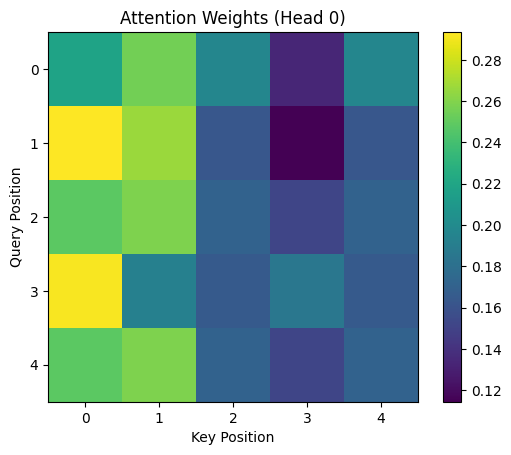


Linear1 Output (before activations): tensor([[[ 0.0138, -0.0656,  0.0682,  0.1331, -0.1139,  0.1239, -0.0494,
          -0.7386,  0.1220,  0.5065,  1.3411,  0.1792,  1.3405, -0.7126,
          -0.1516,  0.6438],
         [ 0.7370, -0.3952,  0.2367,  1.2703,  0.4134, -0.6298, -0.4823,
          -0.5466, -0.4772,  0.5956,  0.5807,  0.0629,  1.1211, -0.3921,
           0.3016, -0.2241],
         [ 0.6141, -1.5166, -0.3412,  1.6869, -0.8923,  0.7661,  0.5853,
          -0.2959,  1.0819,  0.8674,  1.0576,  0.8186,  0.4539,  0.1695,
           0.3556,  0.6344],
         [ 0.2966, -1.2805, -0.6972, -0.0162, -1.4311,  0.2703, -0.2139,
          -0.1721,  0.9535, -0.0261,  0.8443,  0.6822, -0.5474, -0.1840,
           0.6700,  0.2027],
         [ 0.6141, -1.5166, -0.3412,  1.6869, -0.8923,  0.7661,  0.5853,
          -0.2959,  1.0819,  0.8674,  1.0576,  0.8186,  0.4539,  0.1695,
           0.3556,  0.6344]]], grad_fn=<ViewBackward0>)

Final Output after Transformer Block: tensor([[[ 0.9326,  0

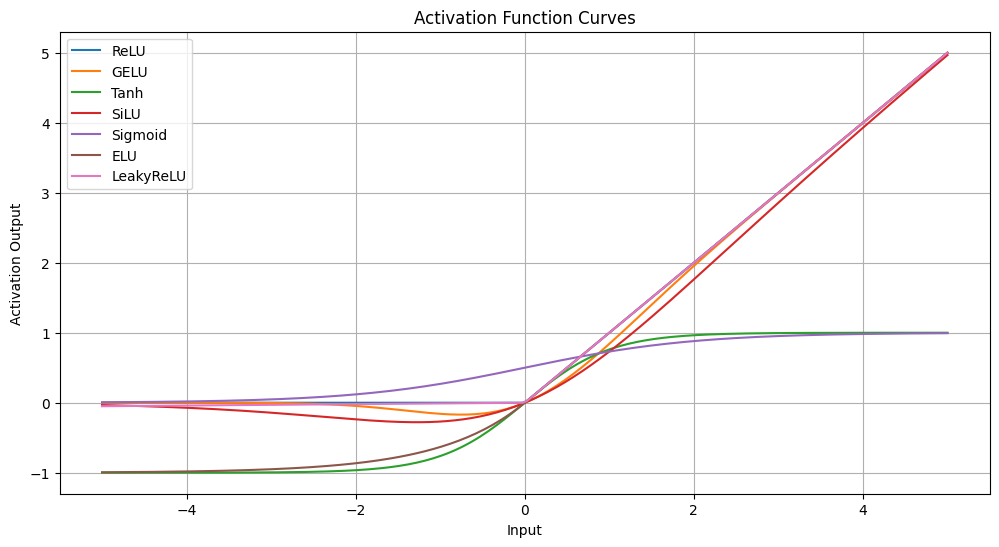

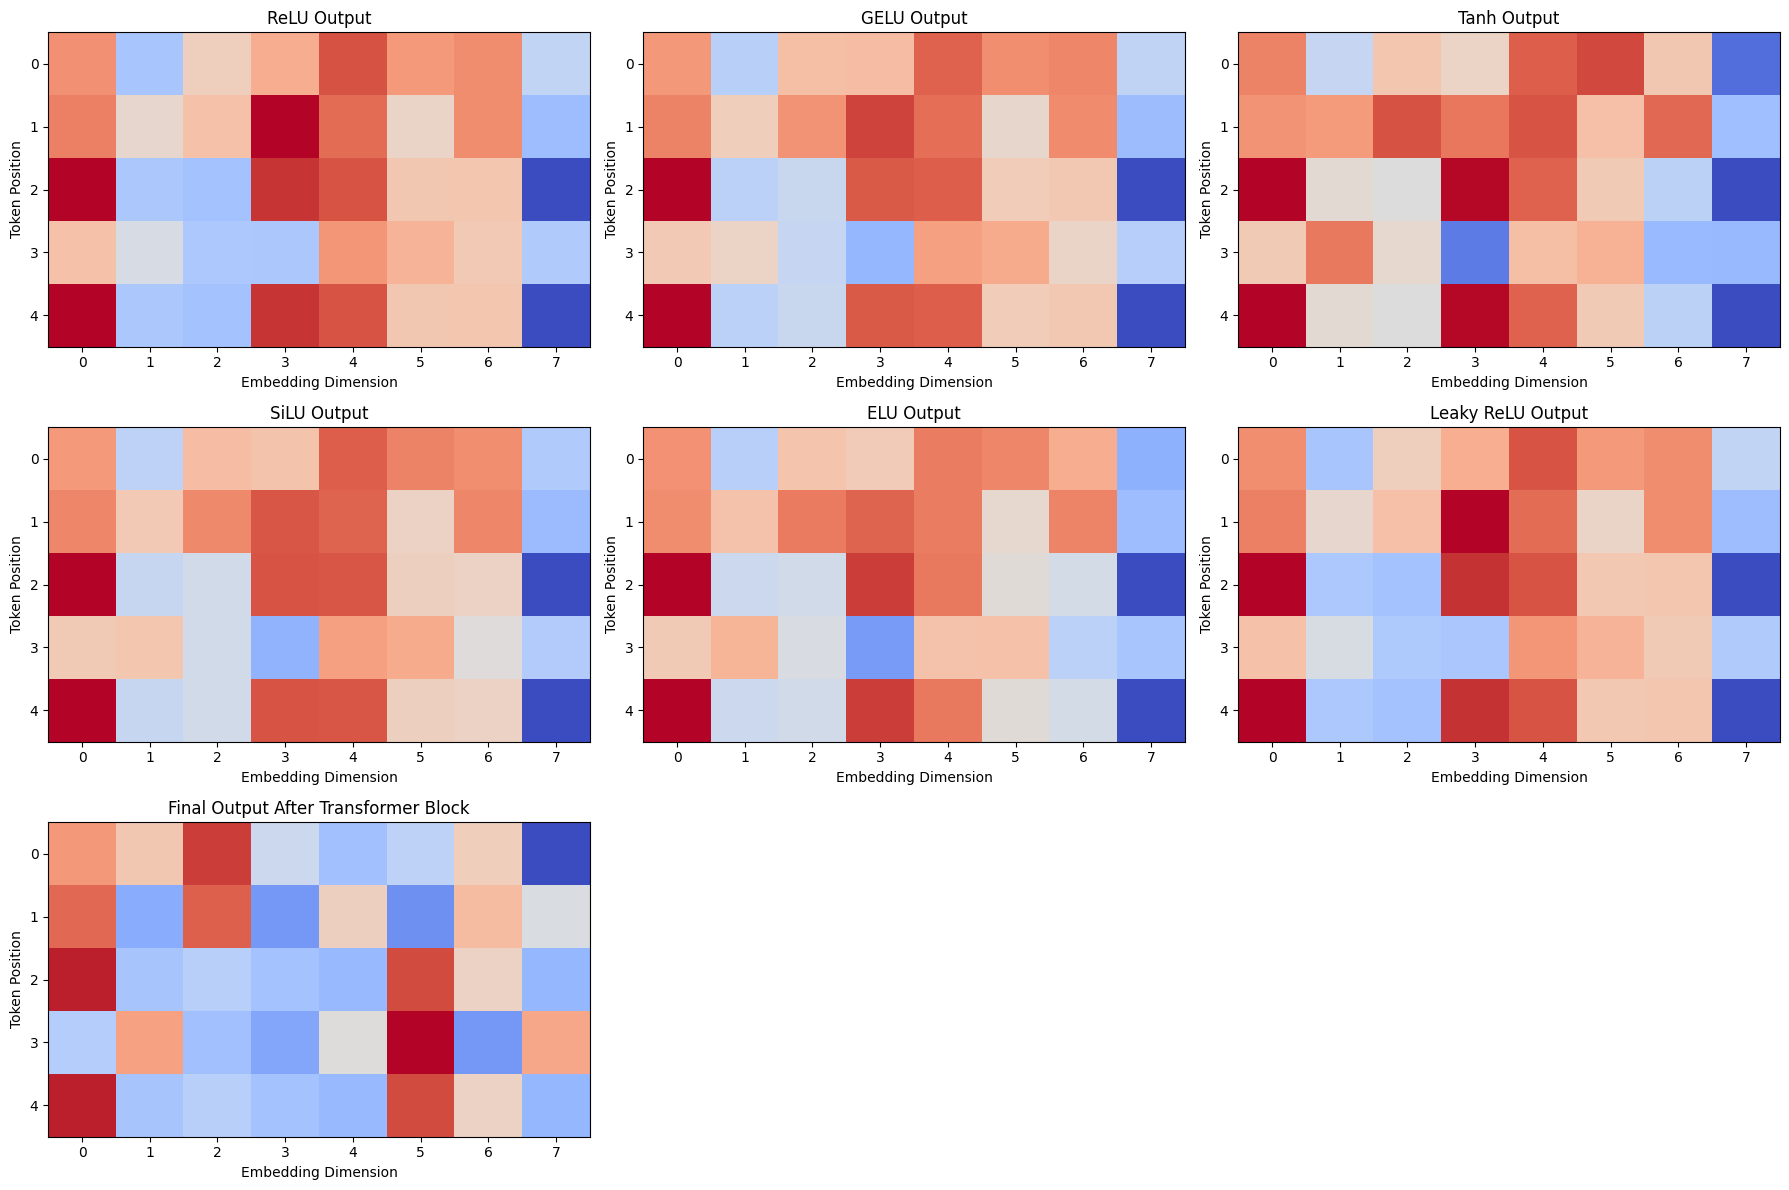

In [9]:
# Transformer Attention Mechanism Demonstration (PyTorch)

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
import numpy as np

# Set random seed for reproducibility
torch.manual_seed(42)

# 1. Sample Input Tokens
vocab_size = 10
embedding_dim = 8
sequence_length = 5
batch_size = 1

# Simulated input token indices (batch_size x sequence_length)
tokens = torch.randint(0, vocab_size, (batch_size, sequence_length))
print("Input Tokens:", tokens)

# 2. Token + Positional Embeddings
embedding = nn.Embedding(vocab_size, embedding_dim)
pos_embedding = nn.Parameter(torch.zeros(1, sequence_length, embedding_dim))

x = embedding(tokens) + pos_embedding  # (batch_size, seq_len, embed_dim)
print("\nToken + Positional Embeddings:", x)

# 3. Scaled Dot-Product Attention
class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_k):
        super().__init__()
        self.scale = math.sqrt(d_k)

    def forward(self, Q, K, V):
        attn_logits = Q @ K.transpose(-2, -1) / self.scale
        attn_weights = F.softmax(attn_logits, dim=-1)
        output = attn_weights @ V
        return output, attn_weights

# 4. Multi-Head Attention (Single Layer Demonstration)
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super().__init__()
        self.num_heads = num_heads
        self.d_k = embed_dim // num_heads

        self.W_q = nn.Linear(embed_dim, embed_dim)
        self.W_k = nn.Linear(embed_dim, embed_dim)
        self.W_v = nn.Linear(embed_dim, embed_dim)
        self.W_o = nn.Linear(embed_dim, embed_dim)

        self.attn = ScaledDotProductAttention(self.d_k)

    def forward(self, x):
        B, T, C = x.shape

        # Linear projections
        Q = self.W_q(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(B, T, self.num_heads, self.d_k).transpose(1, 2)

        # Apply attention
        out, attn_weights = self.attn(Q, K, V)
        out = out.transpose(1, 2).contiguous().view(B, T, C)

        return self.W_o(out), attn_weights

# 5. Instantiate and Run Attention
num_heads = 2
mha = MultiHeadAttention(embed_dim=embedding_dim, num_heads=num_heads)
attn_output, attn_weights = mha(x)

print("\nAttention Output:", attn_output)
print("\nAttention Weights (Head 0):\n", attn_weights[0, 0])

# 6. Visualize Attention Weights for Head 0
plt.imshow(attn_weights[0, 0].detach().numpy(), cmap='viridis')
plt.colorbar()
plt.title("Attention Weights (Head 0)")
plt.xlabel("Key Position")
plt.ylabel("Query Position")
plt.show()

# 7. Add & Norm + Feed Forward
class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, ff_hidden_dim):
        super().__init__()
        self.mha = MultiHeadAttention(embed_dim, num_heads)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.linear1 = nn.Linear(embed_dim, ff_hidden_dim)
        self.relu = nn.ReLU()
        self.gelu = nn.GELU()
        self.tanh = nn.Tanh()
        self.silu = nn.SiLU()
        self.elu = nn.ELU()
        self.leaky_relu = nn.LeakyReLU()
        self.linear2 = nn.Linear(ff_hidden_dim, embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        attn_out, _ = self.mha(x)
        x = self.norm1(x + attn_out)

        lin1_out = self.linear1(x)
        relu_out = self.linear2(self.relu(lin1_out))
        gelu_out = self.linear2(self.gelu(lin1_out))
        tanh_out = self.linear2(self.tanh(lin1_out))
        silu_out = self.linear2(self.silu(lin1_out))
        elu_out = self.linear2(self.elu(lin1_out))
        leaky_relu_out = self.linear2(self.leaky_relu(lin1_out))

        #using the elu activation function
        x = self.norm2(x + elu_out)
        return x, lin1_out, relu_out, gelu_out, tanh_out, silu_out, elu_out, leaky_relu_out

# 8. Run Full Transformer Block & Show MLP Internals
block = TransformerBlock(embedding_dim, num_heads, ff_hidden_dim=16)
output, lin1_out, relu_out, gelu_out, tanh_out, silu_out, elu_out, leaky_relu_out = block(x)

print("\nLinear1 Output (before activations):", lin1_out)
print("\nFinal Output after Transformer Block:", output)

# 9. Visualize Activation Function Curves
activation_funcs = {
    "ReLU": nn.ReLU(),
    "GELU": nn.GELU(),
    "Tanh": nn.Tanh(),
    "SiLU": nn.SiLU(),
    "Sigmoid": nn.Sigmoid(),
    "ELU": nn.ELU(),
    "LeakyReLU": nn.LeakyReLU()
}
x_vals = torch.linspace(-5, 5, 200)

plt.figure(figsize=(12, 6))
for name, act in activation_funcs.items():
    plt.plot(x_vals.numpy(), act(x_vals).numpy(), label=name)
plt.title("Activation Function Curves")
plt.xlabel("Input")
plt.ylabel("Activation Output")
plt.legend()
plt.grid(True)
#plt.colorbar(label='Activation Scale (Function dependent)')
plt.show()

# 10. Visualize Effects of Each Activation Function
fig, axs = plt.subplots(3, 3, figsize=(18, 12))
axs[0, 0].imshow(relu_out[0].detach().numpy(), cmap='coolwarm', aspect='auto')
axs[0, 0].set_title("ReLU Output")
axs[0, 1].imshow(gelu_out[0].detach().numpy(), cmap='coolwarm', aspect='auto')
axs[0, 1].set_title("GELU Output")
axs[0, 2].imshow(tanh_out[0].detach().numpy(), cmap='coolwarm', aspect='auto')
axs[0, 2].set_title("Tanh Output")
axs[1, 0].imshow(silu_out[0].detach().numpy(), cmap='coolwarm', aspect='auto')
axs[1, 0].set_title("SiLU Output")
axs[1, 1].imshow(elu_out[0].detach().numpy(), cmap='coolwarm', aspect='auto')
axs[1, 1].set_title("ELU Output")
axs[1, 2].imshow(leaky_relu_out[0].detach().numpy(), cmap='coolwarm', aspect='auto')
axs[1, 2].set_title("Leaky ReLU Output")
axs[2, 0].imshow(output[0].detach().numpy(), cmap='coolwarm', aspect='auto')
axs[2, 0].set_title("Final Output After Transformer Block")
axs[2, 1].axis('off')
axs[2, 2].axis('off')

for ax in axs.flat:
    if ax.get_title():
        ax.set_xlabel("Embedding Dimension")
        ax.set_ylabel("Token Position")

plt.tight_layout()
plt.show()